# Figure panels for tracks data processing and effective $k_\mathrm{obs}$ fits

## Imports

- Calcium tracks data processing functions are in the `analysis/tracks.jl` module. 
- Functions that make final, detailed plots are in `analysis/tracksPlots.jl`. 
- Functions to fit a one-step model for effective activation rates $k_\mathrm{obs}$ are in `analysis/modelsML.jl`. 

In [1]:
using DataFrames: DataFrames as DF  # all methods available as DF.method
using Plots: Plots as pl
using Printf: @sprintf
using Measures: mm

# 
module tracksAnalysis
    include("analysis/tracks.jl")
end
using .tracksAnalysis: preptrajdata, findactivtimes_thresh, cleannames, get_csv_file_names

# import small utilities from the plotting scripts
module tracksPlots
    include("analysis/tracksPlots.jl")
end
using .tracksPlots: plot_trajs_activ_cdf


module modelsML
    include("analysis/modelsML.jl")
end
using .modelsML: expocdf, expo_loglhood_1dset


In [2]:
# Default styles
pl.default(
    labelfontsize = 14,
    tickfontsize = 12,
    framestyle = :axes,  # https://docs.juliaplots.org/stable/gallery/gr/generated/gr-ref034/
    yminorgrid = false,
    xminorgrid = false,
    xgrid = false,
    ygrid = false,
    size = (450, 450),
    linewidth = 2.0,
    legendfontsize=10, 
    fontfamily="Arial"
)

# Custom line styles with shorter dashes
ddash = [8, 4]
dotdash = [4, 4, 4]

# Default analysis parameters
default_fluo_factor = 0.8
cdfthreshold = 0.75
# Filtering parameters: maximal start time, minimal traj length
minlength = 50
maxstarttime = 30.0
filter_params = [minlength, maxstarttime]

2-element Vector{Float64}:
 50.0
 30.0

# Example trajectories and thresholding
All trajectories in light gray on one plot (all with annotated transition time perhaps), one colored with thresholding to emphasize the procedure. 

In [3]:
# Main fitting and plotting function for one example
function plot_tracks_thresholding(
        filepath, plotfolder; 
        highlight=1, 
        fluothresh=default_fluo_factor, 
        filterpms=filter_params, 
        cdfthresh=cdfthreshold, 
        dosave=false
    )
    # highlight: which track to highlight. 
    greentrajs = preptrajdata(filepath; ch="MEAN_INTENSITY_CH2", filterpms=filterpms)  # Calcium fluorescence
    fi = basename(filepath)
    fi2 = replace(fi, "0." => "0-")
    fi2 = replace(fi2, ".csv" => "")

    activtimes, activfluos, thresh = findactivtimes_thresh(
        greentrajs; fracabove=fluothresh)
    backgnd = thresh / (1.0 + fluothresh)

    # Make plot
    shortnames, lblconcs = cleannames([fi])
    ppp = plot_trajs_activ_cdf(greentrajs, activtimes, activfluos, thresh, backgnd, 
                    highlight; conclbl=shortnames[1])
    
    display(ppp)
    if dosave
        pl.savefig(ppp, joinpath(plotfolder, "tracks_example_thresholding_$(fi2).pdf"))
        println("Saved tracks examples")
    end
end

plot_tracks_thresholding (generic function with 1 method)

File analyzed: pHELD-AF594_1pM_2.csv
Filtering removed 35 tracks out of 85
Saved tracks examples


Row,000,001,002,004,005,006,007,008,009,010
,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?
1,1611.97,1749.97,2187.19,1389.34,881.655,2714.47,1181.43,2696.46,1897.01,2281.93
2,1475.2,1795.87,2261.12,1291.91,855.351,2652.24,1198.25,2797.45,1875.86,2281.22
3,1410.3,1796.1,2296.14,1346.29,845.129,2495.67,1179.43,2787.46,1918.53,2240.07
4,1355.32,1755.5,2219.1,1318.16,849.231,2391.35,1172.65,2699.76,1935.16,2280.59
5,1363.98,1829.38,2126.12,1260.03,858.84,2336.62,1176.34,2619.6,1848.15,2294.37
6,1501.82,1842.01,2074.68,1258.33,857.624,2369.57,1175.7,2595.21,1876.83,2228.96
7,1481.0,1978.68,2076.44,1225.01,832.591,2319.65,1172.44,2670.35,1832.74,2337.74
8,1532.45,2072.83,2054.96,1266.12,848.481,2381.74,1162.85,2522.09,1840.06,2230.81
9,1484.01,2086.02,2057.18,1257.41,832.208,2363.0,1151.54,2632.16,1874.57,2116.15


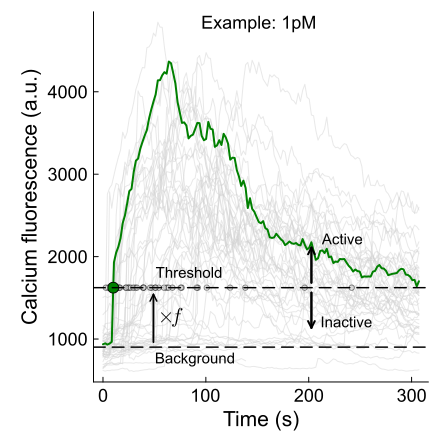

In [4]:
datadir = joinpath("data", "JR064_tracks")
plotfolder = joinpath("figures", "final_tracks_panels")

# Get a cleaned up, sorted list of data file names and paths
fnames, fpaths = get_csv_file_names(datadir)
shortnames, lblconcs = cleannames(fnames)

dset_id = 3
chosenfile = fpaths[dset_id]
println("File analyzed: ", fnames[dset_id])

plot_tracks_thresholding(
    chosenfile, plotfolder;
    highlight=12, 
    dosave=true, 
)

# Effective activation rate $k_\mathrm{obs}$ fitting